# Лабораторная работа № 3. Нелинейные уравнения и системы

Варианты: **IV.12.3 и, ж; IV.12.4 в; IV.12.6 г**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EPS = 1e-8
MAX_ITER = 10000
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
pd.set_option('display.precision', 10)

### Методы
Половинное деление, простая итерация, Ньютон, модифицированный Ньютон. Начальное приближение $x_0$ — конец отрезка, где $f(x_0)f''(x_0)>0$.

Остановка: $(b-a)/2\leq\varepsilon$; $|f(x)|/m\leq\varepsilon$, где $m\leq\min|f'|$ на отрезке; для систем $\|z-\Phi(z)\|_\infty/(1-q)\leq\varepsilon$, где $q\geq\max\|\Phi'\|_\infty$ в области.

In [2]:
def bisection(f, a, b, eps=EPS):
    fa = f(a)
    if fa * f(b) > 0:
        raise ValueError('На концах отрезка нет смены знака')
    history = [(b - a) / 2]
    for _ in range(MAX_ITER):
        if history[-1] <= eps:
            return (a + b) / 2, history
        c = (a + b) / 2
        fc = f(c)
        if fa * fc <= 0:
            b = c
        else:
            a, fa = c, fc
        history.append((b - a) / 2)
    raise RuntimeError('Половинное деление не сошлось')


def scalar_iteration(f, df, phi, x0, interval, m, method, eps=EPS):
    a, b = interval
    x, d0 = x0, df(x0)
    history = [abs(f(x)) / m]
    for _ in range(MAX_ITER):
        if history[-1] <= eps:
            return x, history
        if method == 'Простая итерация':
            x = phi(x)
        elif method == 'Ньютон':
            x = x - f(x) / df(x)
        else:
            x = x - f(x) / d0
        if not a <= x <= b:
            raise RuntimeError('Итерация вышла из отрезка')
        history.append(abs(f(x)) / m)
    raise RuntimeError('Скалярный метод не сошёлся')

### IV.12.3 и
$x^2-e^x/5=0$. Три корня: уравнение равносильно $x^2e^{-x}=1/5$, а $x^2e^{-x}$ убывает от $+\infty$ до $0$ на $(-\infty,0]$, растёт до $4e^{-2}>1/5$ на $[0,2]$ и убывает до $0$ на $[2,\infty)$. Корни лежат на $[-0.5,0]$, $[0.5,1]$, $[4.5,5]$; уточняем второй.

$[a,b]=[0.5,1]$, $x_0=1$, $m=0.67$; $\varphi(x)=e^{x/2}/\sqrt5$, $q=0.37$. Здесь $\varphi([a,b])\subset[a,b]$.

In [3]:
f1 = lambda x: x**2 - np.exp(x)/5
df1 = lambda x: 2*x - np.exp(x)/5
phi1 = lambda x: np.exp(x/2)/np.sqrt(5)

### IV.12.3 ж
$2\,\mathrm{tg}\,x-x/2+1=0$. Корней бесконечно много: на каждом интервале $(\pi k-\pi/2,\ \pi k+\pi/2)$ функция растёт ($f'\geq3/2$) от $-\infty$ до $+\infty$, поэтому там ровно один корень. Ближайшие к нулю лежат на $[-4.5,-4]$, $[-1,-0.5]$, $[3.5,4]$; уточняем корень при $k=0$.

$[a,b]=[-1,-0.5]$, $x_0=-1$, $m=2$; $\varphi(x)=\operatorname{arctg}(x/4-1/2)$, $q=0.18$. Здесь $\varphi([a,b])\subset[a,b]$.

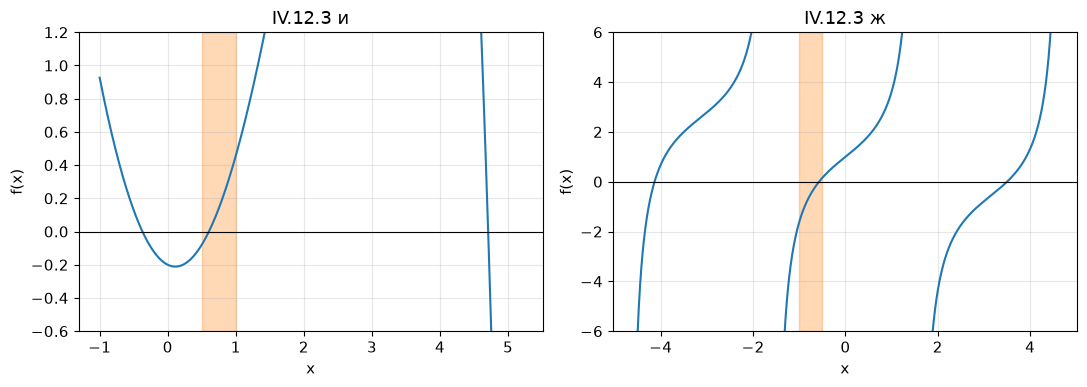

In [4]:
f2 = lambda x: 2*np.tan(x) - x/2 + 1
df2 = lambda x: 2/np.cos(x)**2 - 0.5
phi2 = lambda x: np.arctan(x/4 - 0.5)

scalar_tasks = [
    dict(name='IV.12.3 и', f=f1, df=df1, phi=phi1,
         interval=(0.5, 1.), x0=1., m=0.67, q=0.37,
         view=(-1., 5.2), ylim=(-0.6, 1.2)),
    dict(name='IV.12.3 ж', f=f2, df=df2, phi=phi2,
         interval=(-1., -0.5), x0=-1., m=2., q=0.18,
         view=(-4.6, 4.6), ylim=(-6., 6.))
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, task in zip(axes, scalar_tasks):
    grid = np.linspace(*task['view'], 2000)
    values = task['f'](grid)
    values[np.abs(values) > 12] = np.nan
    ax.plot(grid, values)
    ax.axhline(0, color='black', lw=0.8)
    ax.axvspan(*task['interval'], color='tab:orange', alpha=0.3)
    ax.set(title=task['name'], xlabel='x', ylabel='f(x)', ylim=task['ylim'])
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
methods = ['Половинное деление', 'Простая итерация',
           'Ньютон', 'Модифицированный Ньютон']
scalar_rows = []
scalar_histories = {}
for task in scalar_tasks:
    f = task['f']
    reference, _ = bisection(f, *task['interval'], eps=1e-13)
    for method in methods:
        if method == 'Половинное деление':
            root, history = bisection(f, *task['interval'])
        else:
            root, history = scalar_iteration(
                f, task['df'], task['phi'], task['x0'],
                task['interval'], task['m'], method)
        scalar_histories[(task['name'], method)] = history
        scalar_rows.append({
            'Задача': task['name'], 'Метод': method, 'x': root,
            'Итерации': len(history)-1, '|f(x)|': abs(f(root)),
            'Оценка ошибки': history[-1],
            'Ошибка относительно проверки': abs(root-reference)
        })
scalar_table = pd.DataFrame(scalar_rows)
display(scalar_table)

,Задача,Метод,x,Итерации,|f(x)|,Оценка ошибки,Ошибка относительно проверки
0,IV.12.3 и,Половинное деление,0.6052671149,25,5.3836380354e-09,7.4505805969e-09,6.3773200054e-09
1,IV.12.3 и,Простая итерация,0.6052671288,15,6.3232569181e-09,9.4376968926e-09,7.4903532266e-09
2,IV.12.3 и,Ньютон,0.6052671221,4,6.7129851677e-10,1.0019380847e-09,7.9519524299e-10
3,IV.12.3 и,Модифицированный Ньютон,0.6052671261,20,4.0317589267e-09,6.0175506369e-09,4.7759063371e-09
4,IV.12.3 ж,Половинное деление,-0.5713179037,25,2.0138075651e-09,7.4505805969e-09,8.6555473899e-10
5,IV.12.3 ж,Простая итерация,-0.5713179050,11,4.9896557996e-09,2.4948278998e-09,2.1446864285e-09
6,IV.12.3 ж,Ньютон,-0.5713179028,5,1.0658141036e-13,5.3290705182e-14,9.8809849192e-15
7,IV.12.3 ж,Модифицированный Ньютон,-0.5713179093,38,1.5048949420e-08,7.5244747100e-09,6.4685501400e-09


### IV.12.4 в
$$\begin{cases}\cos(x-1)+y=0.5,\\x-\cos y=3.\end{cases}$$
Точность по условию: $10^{-3}$. $\Phi=(3+\cos y,\ 0.5-\cos(x-1))$.

Рабочая область $D=[3.1,3.55]\times[1,1.36]$, $z_0=(3.325,1.18)$: $\Phi(D)\subset D$, $\|\Phi'\|_\infty<0.978$.

Все решения лежат в $[2,4]\times[-0.5,1.5]$ и сводятся к $h(x)=x-3-\cos(0.5-\cos(x-1))=0$ на $[2,4]$. Здесь $h'\geq1-\sin1.5>0$, а на концах разные знаки: решение одно.

### IV.12.6 г
$$\begin{cases}\sin x-y=1.32,\\\cos y-x=-0.85.\end{cases}$$
Точность по условию: $10^{-5}$. $\Phi=(0.85+\cos y,\ \sin x-1.32)$.

$D=[1.6,1.85]\times[-0.45,-0.3]$, $z_0=(1.725,-0.375)$: $\Phi(D)\subset D$, $\|\Phi'\|_\infty<0.44$.

Все решения лежат в $[-0.15,1.85]\times[-1.47,-0.32]$ и сводятся к $h(x)=x-0.85-\cos(\sin x-1.32)=0$ на $[-0.15,1.85]$. Здесь $h'\geq1-\sin1.47>0$, а на концах разные знаки: точка пересечения одна.

### Методы для систем
Решаем $F(z)=z-\Phi(z)=0$, $J=I-\Phi'(z)$. В таблице — невязка исходной системы.

In [6]:
phi_v = lambda z: np.array([3 + np.cos(z[1]),
                            0.5 - np.cos(z[0] - 1)])
dphi_v = lambda z: np.array([[0., -np.sin(z[1])],
                             [np.sin(z[0] - 1), 0.]])
original_v = lambda z: np.array([np.cos(z[0]-1)+z[1]-0.5,
                                 z[0]-np.cos(z[1])-3])

phi_g = lambda z: np.array([0.85 + np.cos(z[1]),
                            np.sin(z[0]) - 1.32])
dphi_g = lambda z: np.array([[0., -np.sin(z[1])],
                             [np.cos(z[0]), 0.]])
original_g = lambda z: np.array([np.sin(z[0])-z[1]-1.32,
                                 np.cos(z[1])-z[0]+0.85])

system_tasks = [
    dict(name='IV.12.4 в', phi=phi_v, dphi=dphi_v, original=original_v,
         lower=np.array([3.1, 1.]), upper=np.array([3.55, 1.36]),
         z0=np.array([3.325, 1.18]), q=0.978, required=1e-3),
    dict(name='IV.12.6 г', phi=phi_g, dphi=dphi_g, original=original_g,
         lower=np.array([1.6, -0.45]), upper=np.array([1.85, -0.3]),
         z0=np.array([1.725, -0.375]), q=0.44, required=1e-5)
]


def norm(v):
    return np.linalg.norm(v, ord=np.inf)


def system_iteration(task, method, eps=EPS):
    phi, dphi, q = task['phi'], task['dphi'], task['q']
    z = task['z0'].copy()
    J0 = np.eye(2) - dphi(z)
    history = [norm(z - phi(z)) / (1 - q)]
    for _ in range(MAX_ITER):
        if history[-1] <= eps:
            return z, history
        if method == 'Простая итерация':
            z = phi(z)
        else:
            J = np.eye(2) - dphi(z) if method == 'Ньютон' else J0
            z = z - np.linalg.solve(J, z - phi(z))
        if np.any(z < task['lower']) or np.any(z > task['upper']):
            raise RuntimeError('Итерация вышла из прямоугольника')
        history.append(norm(z - phi(z)) / (1 - q))
    raise RuntimeError('Метод для системы не сошёлся')

In [7]:
system_rows = []
system_histories = {}
system_roots = {}
for task in system_tasks:
    reference, _ = system_iteration(task, 'Простая итерация', eps=1e-13)
    for method in methods[1:]:
        root, history = system_iteration(task, method)
        system_roots[(task['name'], method)] = root
        system_histories[(task['name'], method)] = history
        system_rows.append({
            'Задача': task['name'], 'Метод': method,
            'x': root[0], 'y': root[1], 'Итерации': len(history)-1,
            'Невязка исходной системы': norm(task['original'](root)),
            'Оценка ошибки координат': history[-1],
            'Ошибка относительно проверки': norm(root-reference)
        })
system_table = pd.DataFrame(system_rows)
display(system_table)

,Задача,Метод,x,y,Итерации,Невязка исходной системы,Оценка ошибки координат,Ошибка относительно проверки
0,IV.12.4 в,Простая итерация,3.3559117390,1.2069068174,93,2.1207624545e-10,9.6398242923e-09,1.3321610481e-10
1,IV.12.4 в,Ньютон,3.3559117388,1.2069068175,3,2.2204460493e-16,1.0092936588e-14,1.3322676296e-15
2,IV.12.4 в,Модифицированный Ньютон,3.3559117388,1.2069068175,5,1.2787215731e-11,5.8124212514e-10,8.8564711120e-12
3,IV.12.6 г,Простая итерация,1.7913386083,-0.3442210344,13,2.3780521996e-09,4.2465217850e-09,1.9843786614e-09
4,IV.12.6 г,Ньютон,1.7913386100,-0.3442210364,3,1.8340884367e-12,3.2752570497e-12,1.6913692669e-12
5,IV.12.6 г,Модифицированный Ньютон,1.7913386094,-0.3442210370,6,7.1173711369e-10,1.2709592307e-09,5.8712895656e-10


### Проверка модифицированного Ньютона
Для $T(z)=z-J_0^{-1}F(z)$ проверяем сжатие и сохранение прямоугольника:
$$|T'|\leq B=|J_0^{-1}|M,\quad\|B\|_\infty<1,\quad|T(z_0)-z_0|+Br\leq r.$$
$M$ — границы отклонения $\Phi'$ от $\Phi'(z_0)$ в $D$, $r$ — полуширины $D$. Элементы $\Phi'$ в $D$ монотонны: достаточно углов области.

In [8]:
modified_checks = []
for task in system_tasks:
    z0 = task['z0']
    A0 = task['dphi'](z0)
    corners = [np.array([x, y]) for x in [task['lower'][0], task['upper'][0]]
               for y in [task['lower'][1], task['upper'][1]]]
    M = np.max([np.abs(task['dphi'](z)-A0) for z in corners], axis=0)
    J0 = np.eye(2) - A0
    B = np.abs(np.linalg.inv(J0)) @ M
    r = (task['upper']-task['lower'])/2
    first_step = np.linalg.solve(J0, -(z0-task['phi'](z0)))
    invariant = np.all(np.abs(first_step)+B@r <= r)
    modified_checks.append({'Задача': task['name'], 'Верхняя оценка q': norm(B),
                            'Прямоугольник сохраняется': bool(invariant)})
    assert norm(B) < 1 and invariant
    assert np.allclose(z0, (task['lower']+task['upper'])/2)
display(pd.DataFrame(modified_checks))

,Задача,Верхняя оценка q,Прямоугольник сохраняется
0,IV.12.4 в,0.1441964519,True
1,IV.12.6 г,0.1280567411,True


### Кривые систем и сходимость

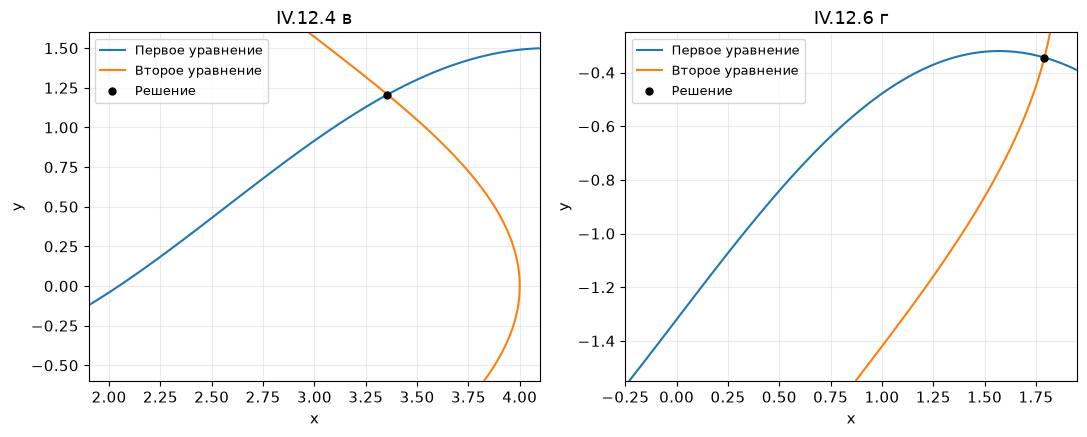

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_domains = [(1.9, 4.1, -0.6, 1.6), (-0.25, 1.95, -1.55, -0.25)]
for ax, task, domain in zip(axes, system_tasks, plot_domains):
    xmin, xmax, ymin, ymax = domain
    X, Y = np.meshgrid(np.linspace(xmin, xmax, 500),
                       np.linspace(ymin, ymax, 500))
    Z = task['original']([X, Y])
    ax.contour(X, Y, Z[0], levels=[0], colors=['tab:blue'])
    ax.contour(X, Y, Z[1], levels=[0], colors=['tab:orange'])
    root = system_roots[(task['name'], 'Ньютон')]
    ax.plot([], [], color='tab:blue', label='Первое уравнение')
    ax.plot([], [], color='tab:orange', label='Второе уравнение')
    ax.plot(*root, 'ko', ms=5, label='Решение')
    ax.set(title=task['name'], xlabel='x', ylabel='y')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

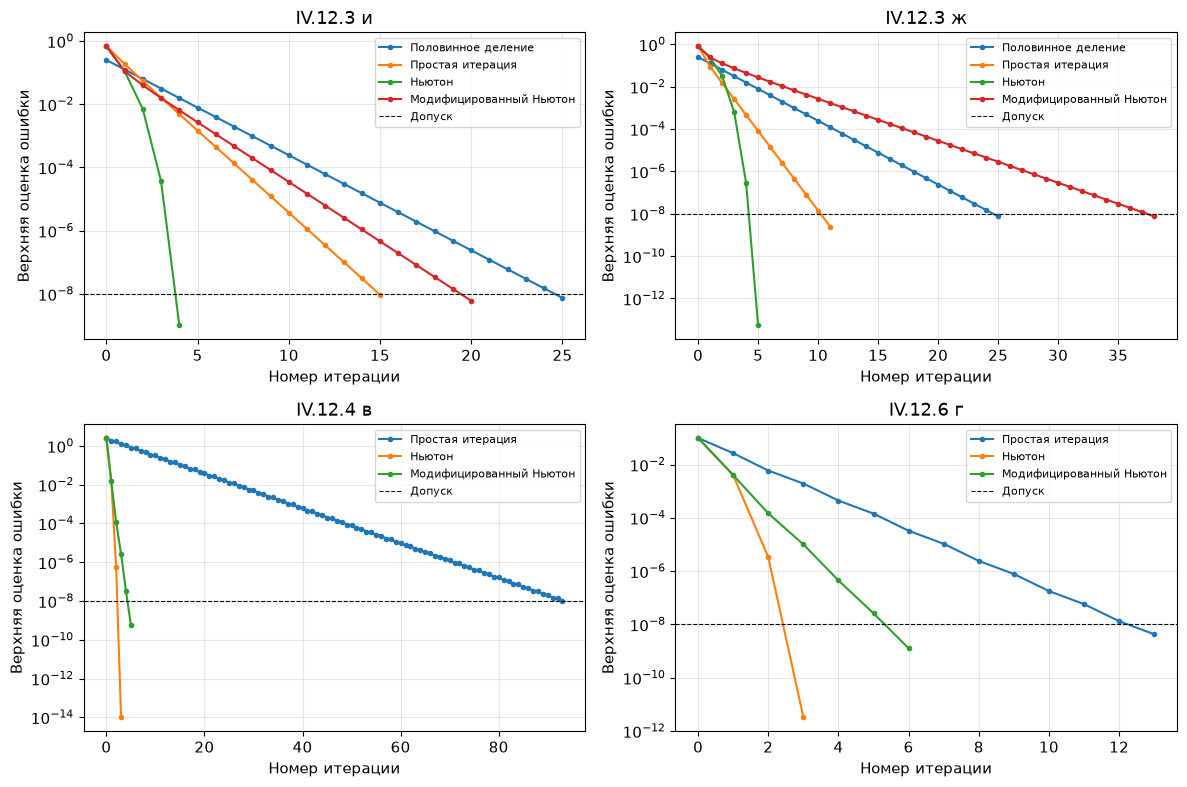

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
all_names = [task['name'] for task in scalar_tasks + system_tasks]
for ax, name in zip(axes.flat, all_names):
    histories = scalar_histories if name.startswith('IV.12.3') else system_histories
    for (task_name, method), history in histories.items():
        if task_name == name:
            ax.semilogy(range(len(history)), np.maximum(history, 1e-16),
                        marker='.', label=method)
    ax.axhline(EPS, color='black', ls='--', lw=0.8, label='Допуск')
    ax.set(title=name, xlabel='Номер итерации', ylabel='Верхняя оценка ошибки')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Ответы и сравнение методов

In [11]:
for task in scalar_tasks:
    row = scalar_table[(scalar_table['Задача'] == task['name'])
                       & (scalar_table['Метод'] == 'Ньютон')].iloc[0]
    print(f"{task['name']}: x = {row['x']:.6f}")
for task, digits in zip(system_tasks, [3, 5]):
    root = system_roots[(task['name'], 'Ньютон')]
    print(f"{task['name']}: x = {root[0]:.{digits}f}, y = {root[1]:.{digits}f}")

assert (scalar_table['Оценка ошибки'] <= EPS).all()
assert (system_table['Оценка ошибки координат'] <= EPS).all()
assert (scalar_table['Ошибка относительно проверки'] <= EPS + 2e-13).all()
assert (system_table['Ошибка относительно проверки'] <= EPS + 2e-13).all()
assert len(scalar_table) == 8 and len(system_table) == 6
print('Все 14 расчётов прошли проверку точности.')

counts = pd.concat([scalar_table, system_table], ignore_index=True)
counts['Итерации'] = counts['Итерации'].astype(str)
display(counts.pivot(index='Задача', columns='Метод', values='Итерации')
        .loc[counts['Задача'].unique(), methods].fillna('—'))

IV.12.3 и: x = 0.605267
IV.12.3 ж: x = -0.571318
IV.12.4 в: x = 3.356, y = 1.207
IV.12.6 г: x = 1.79134, y = -0.34422
Все 14 расчётов прошли проверку точности.


Метод,Половинное деление,Простая итерация,Ньютон,Модифицированный Ньютон
Задача,,,,
IV.12.3 и,25,15,4,20
IV.12.3 ж,25,11,5,38
IV.12.4 в,—,93,3,5
IV.12.6 г,—,13,3,6


**Вывод:** все методы достигли заданной точности и дали согласующиеся ответы. Ньютону хватило 3–5 шагов; простая итерация в IV.12.4 в делает 93 шага, потому что $\Phi$ там сжимает слабо ($\|\Phi'\|_\infty\approx0.93$ в решении), а модифицированный Ньютон в IV.12.3 ж — 38 шагов, потому что $f'$ на отрезке меняется втрое.